# RentWise IDSS: exploratory data analysis and preprocessing
Dataset: UCI *Apartment for Rent Classified* (id 555), 100K file. Raw files in `dataset/raw/` stay unchanged; the cleaning rules live in `scripts/clean_dataset.py` (documented in `dataset/README.md`) and are only *called* here.

In [1]:
import sys; sys.path.insert(0, '..')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scripts.clean_dataset import RAW_DIR, RAW_NAME, clean, ensure_raw_csv, load_raw, normalise_missing

pd.set_option('display.max_columns', 50)
RAW = RAW_DIR / f'{RAW_NAME}.csv'
ensure_raw_csv(RAW)
raw_text = load_raw(RAW)  # all columns as text, exactly as in the file
raw = normalise_missing(raw_text)
for col in ['price','square_feet','bedrooms','bathrooms','latitude','longitude','time']:
    raw[col] = pd.to_numeric(raw[col], errors='coerce')
raw.shape

(100000, 22)

## 1. Structure and types

In [2]:
raw.head(3)

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
0,5668640009,housing/rent/apartment,One BR 507 & 509 Esplanade,"This unit is located at 507 & 509 Esplanade, R...",NaN,1.0,1.0,USD,No,Thumbnail,Cats,2195.0,"$2,195",Monthly,542,507 509 Esplanade,Redondo Beach,CA,33.8520,-118.3759,RentLingo,1577360355
1,5668639818,housing/rent/apartment,Three BR 146 Lochview Drive,"This unit is located at 146 Lochview Drive, Ne...",NaN,1.5,3.0,USD,No,Thumbnail,"Cats,Dogs",1250.0,"$1,250",Monthly,1500,146 Lochview Dr,Newport News,VA,37.0867,-76.4941,RentLingo,1577360340
2,5668639686,housing/rent/apartment,Three BR 3101 Morningside Drive,This unit is located at 3101 Morningside Drive...,NaN,2.0,3.0,USD,No,Thumbnail,None,1395.0,"$1,395",Monthly,1650,3101 Morningside Dr,Raleigh,NC,35.8230,-78.6438,RentLingo,1577360332


In [3]:
raw.dtypes.to_frame('dtype').T

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
dtype,str,str,str,str,str,float64,float64,str,str,str,str,float64,str,str,int64,str,str,str,float64,float64,str,int64


## 2. Missing values

In [4]:
na = raw.isna().sum(); (na[na > 0] / len(raw) * 100).round(2).sort_values(ascending=False).to_frame('% missing')

,% missing
address,92.06
pets_allowed,55.66
amenities,16.09
cityname,0.30
state,0.30
bedrooms,0.12
bathrooms,0.06
latitude,0.02
longitude,0.02
price,0.00


`address` (92%) and `pets_allowed` (56%) are mostly empty, `amenities` 16%. For pets and amenities missing means *not stated*, not *absent*, so we do not impute: `cats_allowed` / `dogs_allowed` stay NA (unknown) when the pet policy is missing, and `amenities_listed` flags whether the listing had an amenity list at all.

## 3. Categorical columns

In [5]:
for c in ['category','price_type','currency','fee','has_photo','pets_allowed','source']:
    print(raw[c].value_counts(dropna=False).head(8), '\n')

category
housing/rent/apartment            99939
housing/rent/commercial/retail       42
housing/rent                          7
housing/rent/home                     4
housing/rent/short_term               4
housing/rent/condo                    3
housing/rent/other                    1
Name: count, dtype: int64 

price_type
Monthly           99996
Weekly                3
Monthly|Weekly        1
Name: count, dtype: int64 

currency
USD    100000
Name: count, dtype: int64 

fee
No     99799
Yes      201
Name: count, dtype: int64 

has_photo
Yes          56252
Thumbnail    34479
No            9269
Name: count, dtype: int64 

pets_allowed
NaN               55663
Cats,Dogs         37279
None               5081
Cats               1849
Dogs                127
Cats,Dogs,None        1
Name: count, dtype: int64 

source
RentDigs.com        91419
RentLingo            6924
ListedBuy             571
GoSection8            437
RealRentals           269
tenantcloud           124
BostonApartments    

Almost everything is `housing/rent/apartment`, monthly, USD. `currency` and `fee` carry (almost) no information.

## 4. Duplicates

In [6]:
k = ['latitude','longitude','price','square_feet','bedrooms','bathrooms']
d = raw.drop_duplicates()
print('exact duplicate rows:', raw.duplicated().sum())
repost_key = k + ['cityname','state','amenities','source']
print('same description + attributes:', d.duplicated(subset=k+['body']).sum())
print('repost rule (attributes + city + amenities + source):', d.duplicated(subset=repost_key).sum())

exact duplicate rows: 84
same description + attributes: 760
repost rule (attributes + city + amenities + source): 11858


In [7]:
rep = d[d.duplicated(subset=repost_key, keep=False)].sort_values(k)
rep[['id','title','price','cityname','time','source']].head(6)

,id,title,price,cityname,time,source
84020,5121994978,This Apartment is a must see!,2024.0,Miami,1544248535,RentDigs.com
87681,5121994858,Two BR Apartment in Quiet Building - Miami,2024.0,Miami,1544248518,RentDigs.com
84163,5121956578,Apartment in move in condition in Miami. Pet OK!,1836.0,Miami,1544244573,RentDigs.com
96898,5121958319,Beautiful Miami Apartment for rent. Single Car...,1836.0,Miami,1544244748,RentDigs.com
95947,5121958783,"Bright Miami, Two BR, Two BA for rent. Pet OK!",3239.0,Miami,1544244805,RentDigs.com
96900,5121958019,"Lovely Miami, Two BR, Two BA",3239.0,Miami,1544244716,RentDigs.com


Reposts are the same unit posted several times, usually minutes apart, with a reworded title and description, so matching on the text misses most of them. The script treats listings as reposts when they agree on price, size, rooms, city, coordinates, amenities and source, and keeps the earliest ad.

## 5. Numeric distributions and outliers

In [8]:
num = raw[['price','square_feet','bedrooms','bathrooms']].copy(); num['price_per_sqft'] = raw.price / raw.square_feet
num.describe(percentiles=[.001,.01,.5,.99,.999]).round(2)

,price,square_feet,bedrooms,bathrooms,price_per_sqft
count,99999.00,100000.00,99876.00,99937.00,99999.00
mean,1527.18,956.43,1.73,1.45,1.69
std,903.24,417.09,0.75,0.55,0.86
min,100.00,101.00,0.00,1.00,0.05
0.1%,400.00,250.00,0.00,1.00,0.40
1%,545.00,397.99,1.00,1.00,0.62
50%,1350.00,900.00,2.00,1.00,1.47
99%,4250.00,2259.00,4.00,3.00,4.67
99.9%,9000.00,3888.01,5.00,4.00,7.22
max,52500.00,50000.00,9.00,9.00,37.02


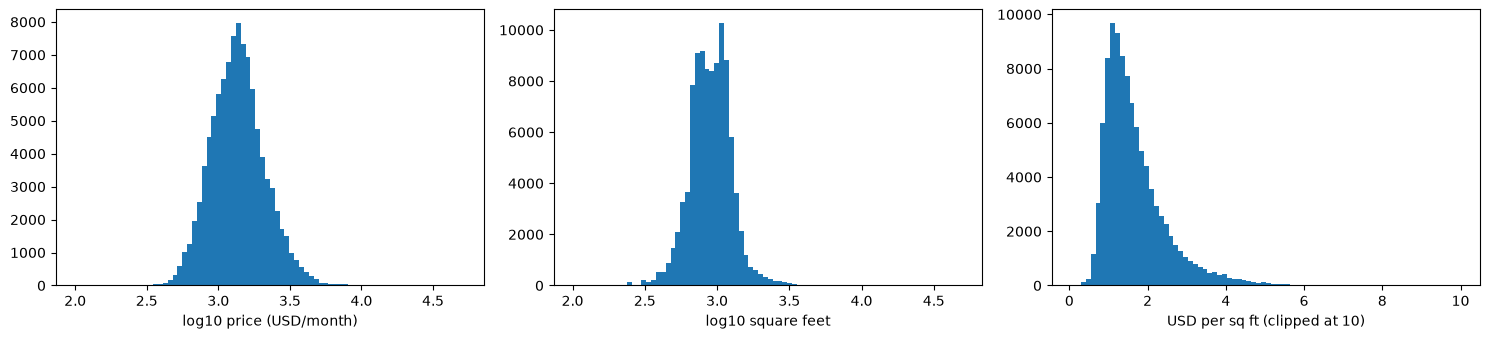

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(np.log10(raw.price.dropna()), bins=80); ax[0].set_xlabel('log10 price (USD/month)')
ax[1].hist(np.log10(raw.square_feet), bins=80); ax[1].set_xlabel('log10 square feet')
ax[2].hist(num.price_per_sqft.clip(upper=10), bins=80); ax[2].set_xlabel('USD per sq ft (clipped at 10)')
plt.tight_layout()

In [10]:
raw.loc[raw.price > 15000, ['price','square_feet','bedrooms','cityname','title']].head(8)

,price,square_feet,bedrooms,cityname,title
3487,25000.0,8716,6.0,Montecito,Six BR 256 Las Entradas
6574,19500.0,5000,4.0,Los Angeles,Four BR 864 Teakwood Rd
6863,52500.0,1418,0.0,Barstow,Studio apartment for rent
14475,30000.0,5872,5.0,Snowmass Village,This mountain contemporary is truly one of a k...
17206,35000.0,2269,4.0,West Hollywood,Four BR - ready to move in.
18400,20000.0,2866,3.0,West Hollywood,"West Hollywood - 3bd/3.25 BA 2,866sqft Apartme..."
23678,25000.0,6881,4.0,Playa Del Rey,Four BR Apartment - Beautiful bluff top proper...
23992,23000.0,3280,3.0,Los Angeles,Three BR Apartment - At The Century you will e...


In [11]:
raw.loc[raw.price < 300, ['price','square_feet','bedrooms','price_type','title']]

,price,square_feet,bedrooms,price_type,title
3769,288.0,766,1.0,Monthly,One BR 1200 Mallard Drive
4417,224.0,587,1.0,Monthly,Studio apartment 116 N 2nd St
6286,200.0,250,1.0,Monthly,One BR Ridge Road
7245,275.0,300,NaN,Monthly|Weekly,A-P-T Suites Lakeland - Low Weekly & Monthly R...
22973,264.0,750,1.0,Monthly,Come home to Auburn Trace Apartments. $264/mo
52249,100.0,800,2.0,Monthly,Park Management LLC
53014,299.0,736,1.0,Monthly,Columbus - 1bd/One BA 736sqft Apartment for re...
53433,200.0,800,0.0,Monthly,"Studio, One BA, safe neighborhood"
84243,285.0,400,1.0,Monthly,Apartment for rent in Talladega. Pet OK!


Above ~10,000 USD the listings are mostly real luxury villas/estates (not errors), but outside the scope of a tool for ordinary renters. Below 300 USD they are weekly rates, rooms or data errors. Both tails are tiny (<0.2%).

## 6. Location

In [12]:
print('placeholder US-centroid coordinates (39.8163, -98.5576):', ((raw.latitude==39.8163)&(raw.longitude==-98.5576)).sum())
print('missing city/state:', raw.cityname.isna().sum())
raw.loc[raw.cityname.isna(), ['latitude','longitude']].value_counts().head(3)

placeholder US-centroid coordinates (39.8163, -98.5576): 220
missing city/state: 302


latitude  longitude
39.8163   -98.5576     220
37.2770   -75.9597      16
37.8286   -92.2006      15
Name: count, dtype: int64

Rows without city/state mostly sit on the geographic centre of the US: a geocoding placeholder, not a real location → drop.

## 7. Run the cleaning pipeline

In [13]:
clean_df, log = clean(raw_text)

In [14]:
pd.DataFrame(log)

,step,removed,remaining
0,Raw file,0,100000
1,Exact duplicate rows,84,99916
2,"Not an apartment (retail, home, condo, short-t...",61,99855
3,Price not quoted per month,4,99851
4,Currency other than USD,0,99851
5,"Missing price, square feet, bedrooms or bathrooms",185,99666
6,Missing or placeholder location,298,99368
7,"Impossible values (non-positive numbers, coord...",0,99368
8,"Price outside $300-$10,000",79,99289
9,"Square feet outside 150-5,000",23,99266


## 8. Cleaned data

In [15]:
clean_df.describe().T[['mean','min','50%','max']].round(2).head(10)

,mean,min,50%,max
price,1546.79,300.00,1379.00,10000.00
square_feet,960.65,150.00,903.00,4970.00
price_per_sqft,1.71,0.32,1.49,9.99
bedrooms,1.73,0.00,2.00,9.00
bathrooms,1.45,1.00,1.00,7.00
latitude,36.94,19.57,37.27,64.83
longitude,-91.43,-159.37,-84.51,-68.78
amenity_ac,0.15,0.00,0.00,1.00
amenity_alarm,0.00,0.00,0.00,1.00
amenity_basketball,0.04,0.00,0.00,1.00


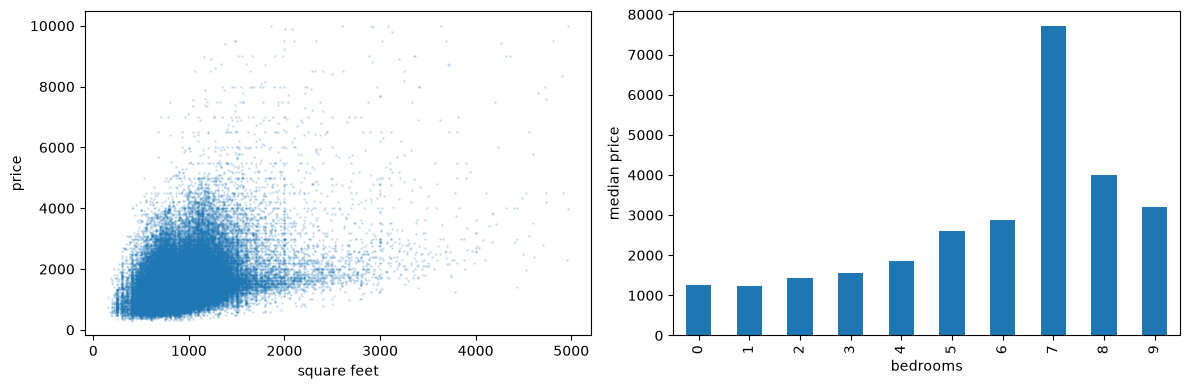

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(clean_df.square_feet, clean_df.price, s=1, alpha=.15); ax[0].set_xlabel('square feet'); ax[0].set_ylabel('price')
clean_df.groupby('bedrooms').price.median().plot.bar(ax=ax[1]); ax[1].set_ylabel('median price')
plt.tight_layout()

In [17]:
clean_df.filter(like='amenity_').mean().sort_values(ascending=False).round(3).to_frame('share of listings').T

,amenity_pool,amenity_parking,amenity_gym,amenity_patio_deck,amenity_washer_dryer,amenity_storage,amenity_clubhouse,amenity_dishwasher,amenity_ac,amenity_fireplace,amenity_refrigerator,amenity_cable_or_satellite,amenity_internet_access,amenity_playground,amenity_wood_floors,amenity_gated,amenity_tennis,amenity_tv,amenity_elevator,amenity_hot_tub,amenity_basketball,amenity_garbage_disposal,amenity_view,amenity_alarm,amenity_luxury,amenity_doorman,amenity_golf
share of listings,0.43,0.427,0.372,0.266,0.263,0.212,0.189,0.166,0.154,0.153,0.151,0.126,0.114,0.107,0.092,0.087,0.086,0.046,0.046,0.041,0.04,0.039,0.022,0.004,0.002,0.002,0.0


The cleaned file keeps all US listings.

In [18]:
clean_df.shape  # the file itself is written by `uv run python scripts/clean_dataset.py`

(87452, 45)